In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

In [2]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

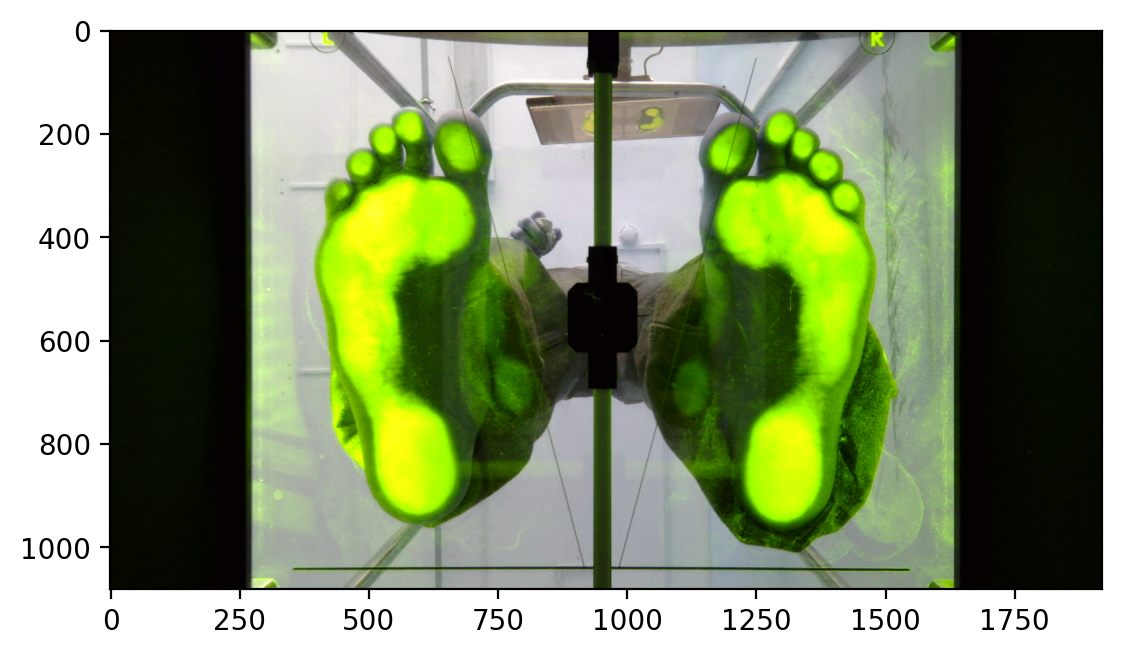

In [3]:
image = cv.imread("./плантограммы/Img (copy 4).png")

plt.imshow(image)

In [4]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    yPad = 50
    assert image.shape == (1080, 1920, 3)
    return image[yPad:,leftPad:880,:], image[yPad:,1025:-rightPad,:]


(1030, 600, 3) (1030, 605, 3)


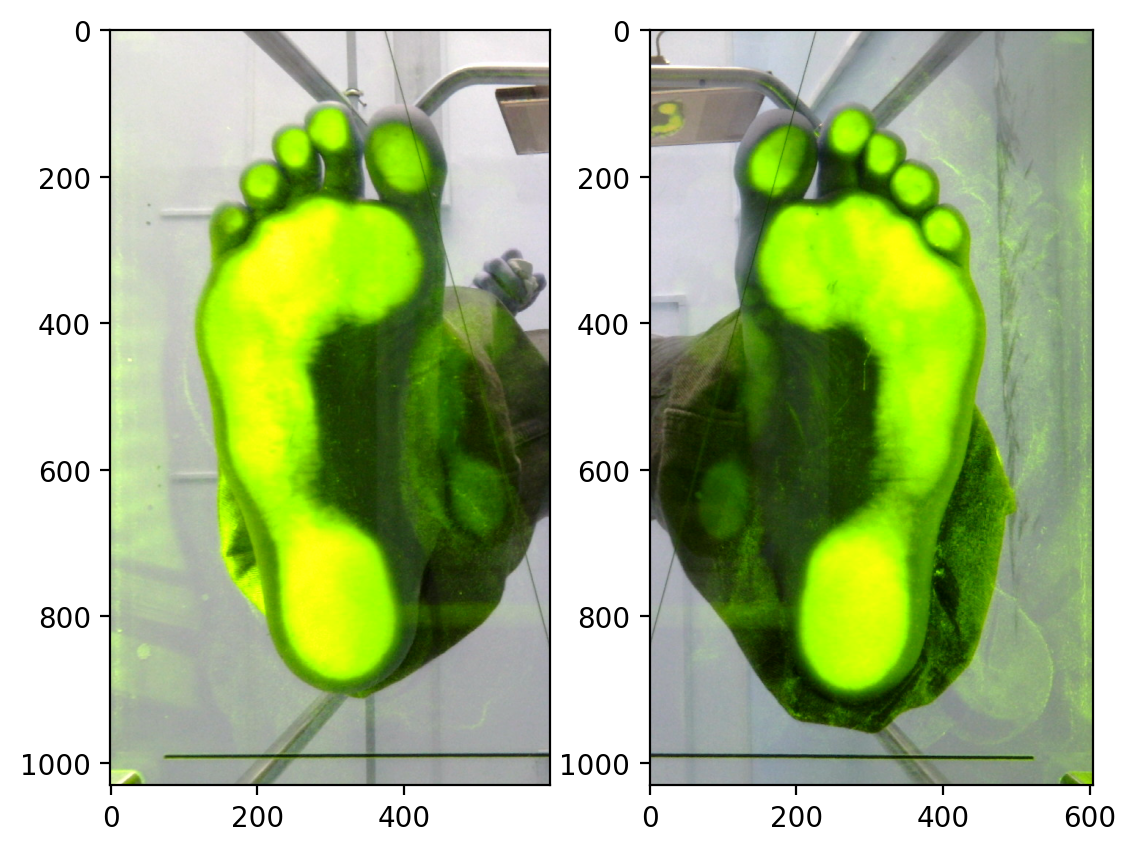

In [5]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)
# ax1.grid(which='major')
# ax1.set_yticks(np.linspace(0, 1100, 65), )
print(footL.shape, footR.shape)

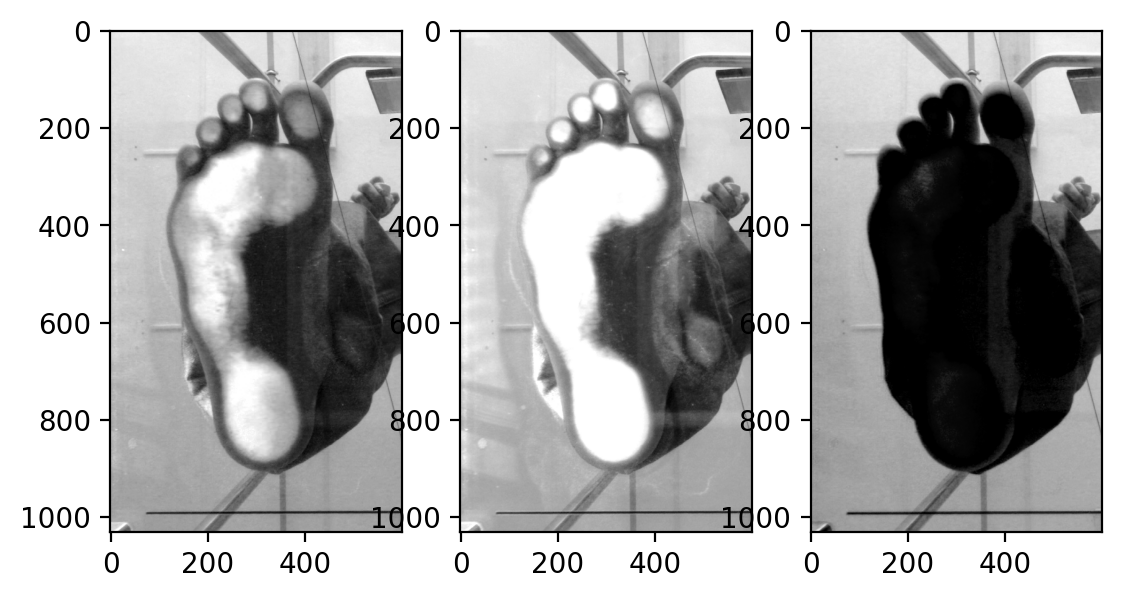

In [17]:
fig, axs = plt.subplots(1,3)

axs[0].imshow(footL[...,0], 'gray')
axs[1].imshow(footL[...,1], 'gray')
axs[2].imshow(footL[...,2], 'gray')



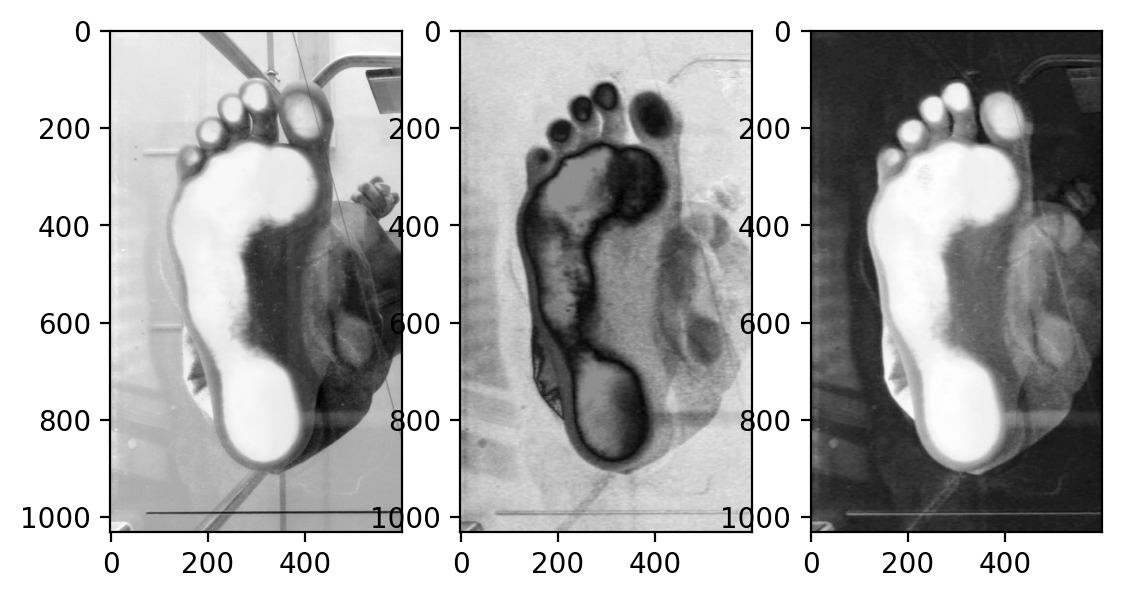

In [18]:
fig, axs = plt.subplots(1,3)

lab = cv.cvtColor(footL, cv.COLOR_RGB2Lab)

axs[0].imshow(lab[...,0], 'gray')
axs[1].imshow(lab[...,1], 'gray')
axs[2].imshow(lab[...,2], 'gray')



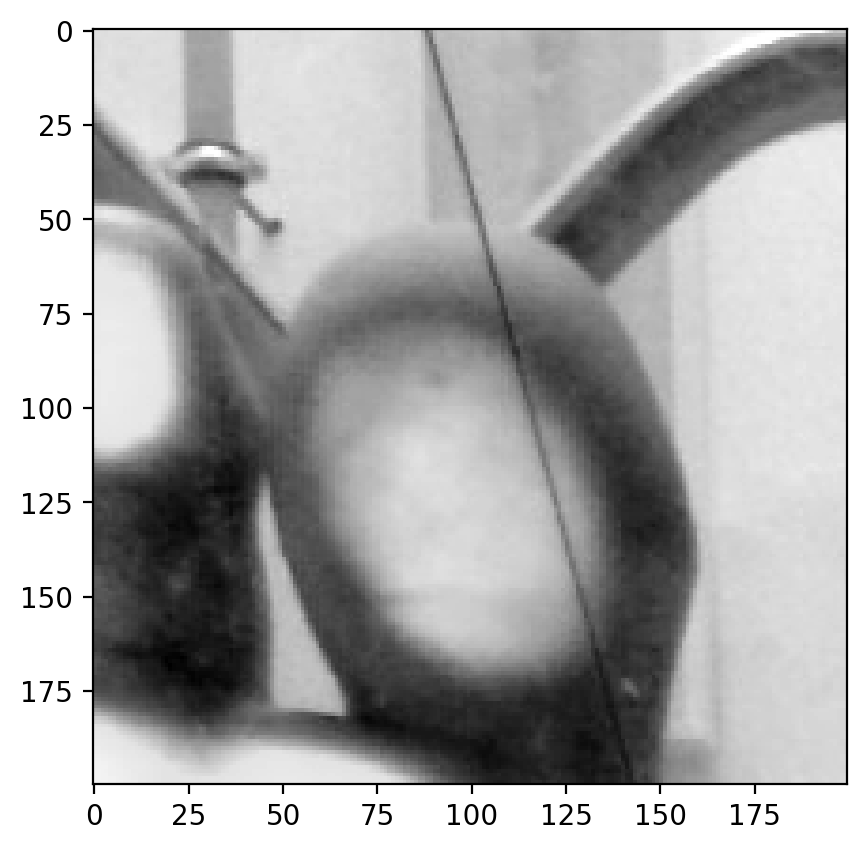

In [28]:
width = 200
height = 200
roi = lab[50:50+height, 300:300+width, 0]
plt.imshow(roi, 'gray')

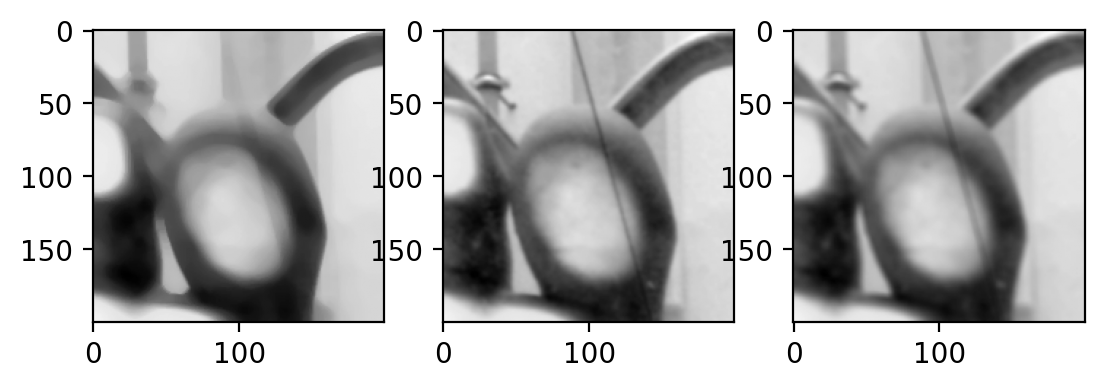

In [70]:
fig, axs = plt.subplots(1, 3)

median = cv.medianBlur(roi,11)
gaussian = cv.GaussianBlur(roi, (5,5), 1)

ksize = 5
kernel = np.ones((ksize, ksize),np.float32)/(ksize * ksize)
average = cv.filter2D(roi,-1,kernel)



axs[0].imshow(median, 'gray')
axs[1].imshow(gaussian, 'gray')
axs[2].imshow(average, 'gray')

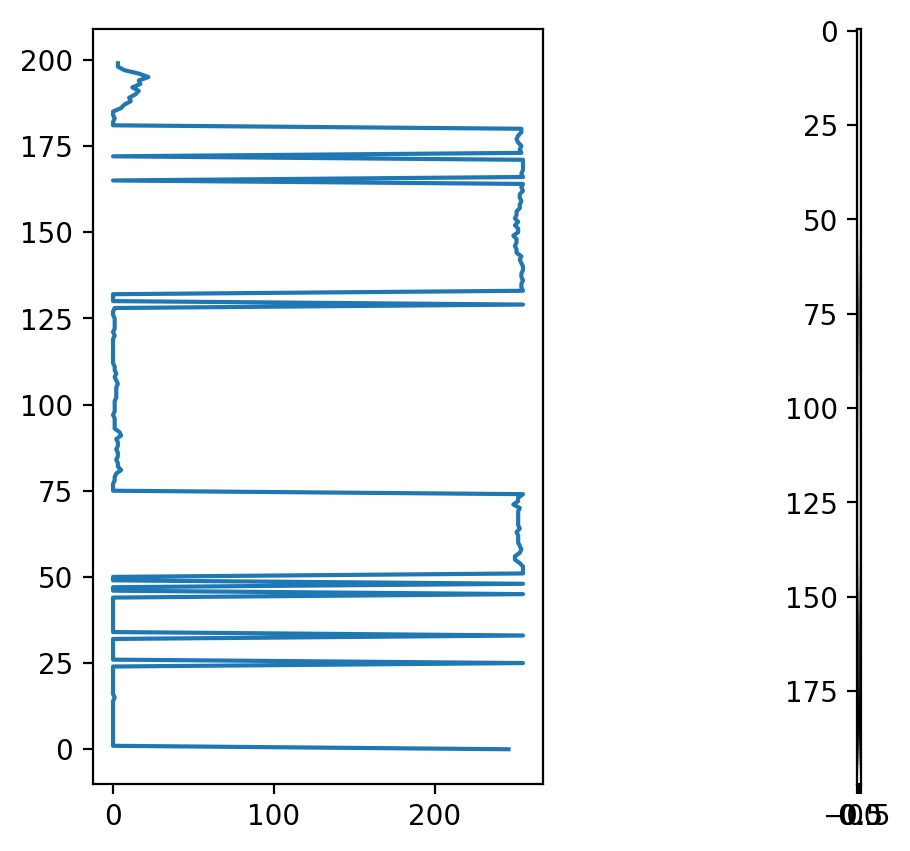

In [69]:
fig, axs = plt.subplots(1, 2)

X = 75

Y = cv.medianBlur(roi, 11)[:,X]

diff = np.roll(Y, 1) - Y

axs[0].plot(-diff, range(len(diff)))


axs[1].imshow(np.expand_dims(Y, 1), 'gray')

In [67]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [40]:
np.roll(a,1) - a

array([ 9, -1, -1, -1, -1, -1, -1, -1, -1, -1])